# 01 — Data acquisition

In [1]:
import json

import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

ee.Initialize(project="caramel-slice-498315-i6")

with open("../forest-jendouba-polygon.geojson") as f:
    gj = json.load(f)

AREA = ee.Geometry.Polygon(gj["features"][0]["geometry"]["coordinates"])
CENTROID = AREA.centroid(maxError=1)

START, END = "2000-03-01", "2024-12-31"

area_m2 = AREA.area().getInfo()
print(f"area {area_m2:,.0f} m2 = {area_m2 / 1e6:.3f} km2")
print(f"  MODIS 250 m : {area_m2 / 250**2:5.1f} pixels")
print(f"  MODIS 1 km  : {area_m2 / 1000**2:5.2f} pixels")

area 998,511 m2 = 0.999 km2
  MODIS 250 m :  16.0 pixels
  MODIS 1 km  :  1.00 pixels


## NDVI — MODIS MOD13Q1

In [2]:
def extract(collection, band, scale, name):
    """Spatial mean, spread and pixel count over the forest, per date."""
    ic = (ee.ImageCollection(collection)
            .filterDate(START, END)
            .filterBounds(AREA)
            .select(band))

    reducer = (ee.Reducer.mean()
                 .combine(ee.Reducer.stdDev(), sharedInputs=True)
                 .combine(ee.Reducer.count(), sharedInputs=True))

    def sample(img):
        stats = img.reduceRegion(reducer=reducer, geometry=AREA, scale=scale)
        return ee.Feature(None, {
            "date": img.date().format("YYYY-MM-dd"),
            name: stats.get(f"{band}_mean"),
            f"{name}_sd": stats.get(f"{band}_stdDev"),
            f"{name}_n": stats.get(f"{band}_count"),
        })

    rows = ee.FeatureCollection(ic.map(sample)).getInfo()["features"]
    df = pd.DataFrame([r["properties"] for r in rows])
    df["date"] = pd.to_datetime(df["date"])
    return df.sort_values("date").reset_index(drop=True)


ndvi = extract("MODIS/061/MOD13Q1", "NDVI", 250, "NDVI")
ndvi[["NDVI", "NDVI_sd"]] *= 0.0001

print(len(ndvi), "composites,",
      ndvi.date.min().date(), "->", ndvi.date.max().date())
print(ndvi[["NDVI", "NDVI_sd", "NDVI_n"]].describe().round(4))

571 composites, 2000-03-05 -> 2024-12-18
           NDVI   NDVI_sd    NDVI_n
count  571.0000  571.0000  571.0000
mean     0.8022    0.0259   24.0823
std      0.0673    0.0251    0.2751
min      0.2613    0.0057   24.0000
25%      0.7777    0.0137   24.0000
50%      0.8188    0.0191   24.0000
75%      0.8432    0.0309   24.0000
max      0.8928    0.2765   25.0000


## LST — MODIS MOD11A2

In [3]:
lst = extract("MODIS/061/MOD11A2", "LST_Day_1km", 1000, "LST")
lst[["LST", "LST_sd"]] *= 0.02
lst["LST"] -= 273.15

print(len(lst), "composites,",
      lst.date.min().date(), "->", lst.date.max().date())
print(lst[["LST", "LST_sd", "LST_n"]].describe().round(3))
print("\nmissing:", lst["LST"].isna().sum())

1141 composites, 2000-03-05 -> 2024-12-26
            LST    LST_sd     LST_n
count  1111.000  1111.000  1141.000
mean     20.680     0.634     3.869
std       7.662     0.433     0.676
min      -1.495     0.000     0.000
25%      14.235     0.285     4.000
50%      20.182     0.551     4.000
75%      27.260     0.897     4.000
max      39.056     3.681     4.000

missing: 30


## SPEI — CSIC SPEIbase v2.11

In [4]:
SPEI_BANDS = ["SPEI_01_month", "SPEI_03_month", "SPEI_06_month", "SPEI_12_month",
              "SPEI_24_month", "SPEI_48_month"]
SPEI_COLS = [f"SPEI_{int(b[5:7])}" for b in SPEI_BANDS]

spei_ic = (ee.ImageCollection("CSIC/SPEI/2_11")
             .filterDate(START, END)
             .filterBounds(AREA)
             .select(SPEI_BANDS))


def sample_spei(img):
    stats = img.reduceRegion(ee.Reducer.first(), CENTROID, 55660)
    return ee.Feature(None, stats.set("date", img.date().format("YYYY-MM-dd")))


rows = ee.FeatureCollection(spei_ic.map(sample_spei)).getInfo()["features"]
spei = pd.DataFrame([r["properties"] for r in rows])
spei["date"] = pd.to_datetime(spei["date"])
spei = (spei.rename(columns=dict(zip(SPEI_BANDS, SPEI_COLS)))
            .sort_values("date").reset_index(drop=True))

print(len(spei), "months,", spei.date.min().date(), "->", spei.date.max().date())
print(spei[SPEI_COLS].describe().round(3))

298 months, 2000-03-01 -> 2024-12-01
        SPEI_1   SPEI_3   SPEI_6  SPEI_12  SPEI_24  SPEI_48
count  298.000  298.000  298.000  298.000  298.000  298.000
mean    -0.278   -0.350   -0.406   -0.492   -0.636   -0.806
std      1.047    1.043    1.049    1.095    1.090    1.039
min     -2.225   -2.612   -2.637   -2.802   -2.884   -3.101
25%     -1.078   -1.194   -1.234   -1.383   -1.433   -1.487
50%     -0.360   -0.362   -0.400   -0.524   -0.739   -0.910
75%      0.534    0.415    0.376    0.315    0.075   -0.195
max      2.235    2.448    2.372    2.055    1.971    1.766


## Quality screening

In [5]:
qa = extract("MODIS/061/MOD13Q1", "SummaryQA", 250, "QA")[["date", "QA"]]
ndvi = ndvi.drop(columns="QA", errors="ignore").merge(qa, on="date", how="left")

CLOUD = ndvi["QA"] >= 2
s = ndvi["NDVI"]
neighbours = (s.shift(1) + s.shift(-1)) / 2

print(f"NDVI composites flagged cloud or snow: {CLOUD.sum()} of {len(ndvi)}\n")
print(ndvi.loc[CLOUD, ["date", "NDVI", "QA"]]
          .assign(date=lambda t: t["date"].dt.date,
                  neighbours=neighbours[CLOUD], deviation=(s - neighbours)[CLOUD])
          .round(3).to_string(index=False))

ndvi.loc[CLOUD, ["NDVI", "NDVI_sd"]] = np.nan


def lst_quality(img):
    qc = img.select("QC_Day")
    flags = ee.Image.cat([qc.bitwiseAnd(3).rename("mandatory"),
                          qc.rightShift(6).bitwiseAnd(3).rename("error")])
    stats = flags.reduceRegion(ee.Reducer.mean(), AREA, 1000)
    return ee.Feature(None, stats.set("date", img.date().format("YYYY-MM-dd")))


rows = ee.FeatureCollection(
    ee.ImageCollection("MODIS/061/MOD11A2")
      .filterDate(START, END).filterBounds(AREA).map(lst_quality)
).getInfo()["features"]
lst_qc = pd.DataFrame([r["properties"] for r in rows])

print(f"\nLST error flag, area-weighted (0: <=1 K, 1: <=2 K, 2: <=3 K, 3: >3 K)")
print(f"  max over record {lst_qc['error'].max():.2f}")
print(f"  composites with estimated error above 2 K: {(lst_qc['error'] > 1).sum()}")

NDVI composites flagged cloud or snow: 10 of 571

      date  NDVI    QA  neighbours  deviation
2001-12-03 0.360 3.000       0.820     -0.460
2002-03-22 0.524 3.000       0.769     -0.244
2003-02-02 0.699 2.378       0.724     -0.025
2004-12-18 0.385 3.000       0.774     -0.389
2010-01-17 0.588 2.937       0.803     -0.216
2012-01-17 0.261 3.000       0.691     -0.429
2012-02-02 0.569 3.000       0.469      0.099
2023-05-09 0.786 3.000       0.841     -0.055
2023-12-03 0.777 2.974       0.840     -0.062
2024-02-18 0.724 3.000       0.740     -0.016



LST error flag, area-weighted (0: <=1 K, 1: <=2 K, 2: <=3 K, 3: >3 K)
  max over record 1.00
  composites with estimated error above 2 K: 0


## Monthly aggregation

In [6]:
ndvi_monthly = ndvi.set_index("date")[["NDVI", "NDVI_sd"]].resample("MS").mean()
lst_monthly  = lst.set_index("date")[["LST", "LST_sd"]].resample("MS").mean()

spei_monthly = spei.set_index("date")[SPEI_COLS]
spei_monthly.index = spei_monthly.index.to_period("M").to_timestamp()

master = ndvi_monthly.join(lst_monthly).join(spei_monthly, how="inner")

print(master.shape)
print(master.isna().sum().to_string())
print(master.head(3).round(4))

(298, 10)
NDVI       0
NDVI_sd    0
LST        0
LST_sd     0
SPEI_1     0
SPEI_3     0
SPEI_6     0
SPEI_12    0
SPEI_24    0
SPEI_48    0
              NDVI  NDVI_sd      LST  LST_sd  SPEI_1  SPEI_3  SPEI_6  SPEI_12  \
date                                                                            
2000-03-01  0.6082   0.0331  17.3707  0.5382 -1.7357 -2.2339 -1.4298  -1.8030   
2000-04-01  0.8380   0.0492  19.9978  0.4339 -0.6947 -1.9320 -1.2856  -1.6968   
2000-05-01  0.8359   0.0245  24.1277  0.6612  0.7090 -1.1561 -1.8439  -1.4755   

            SPEI_24  SPEI_48  
date                          
2000-03-01  -1.2212  -1.1153  
2000-04-01  -1.3100  -1.3724  
2000-05-01  -1.2159  -1.4246  


## Saving

In [7]:
ndvi.to_csv("../data/raw/forest_ndvi_16day.csv", index=False)
lst.to_csv("../data/raw/forest_lst_8day.csv", index=False)
spei.to_csv("../data/raw/forest_spei_monthly.csv", index=False)
master.to_csv("../data/raw/forest_monthly.csv")

print("16-day NDVI", ndvi.shape,
      "| 8-day LST", lst.shape,
      "| SPEI", spei.shape,
      "| monthly", master.shape)

16-day NDVI (571, 5) | 8-day LST (1141, 4) | SPEI (298, 7) | monthly (298, 10)


## Validation

### Checks 1, 2 and 4

In [8]:
clim = master.groupby(master.index.month)[["NDVI", "LST"]].mean().round(3)
print(clim.to_string())

print(f"\nNDVI peaks month {clim['NDVI'].idxmax():2d}, troughs month {clim['NDVI'].idxmin():2d}")
print(f"LST  peaks month {clim['LST'].idxmax():2d}, troughs month {clim['LST'].idxmin():2d}")
print(f"NDVI climatological amplitude: {clim['NDVI'].max() - clim['NDVI'].min():.3f}")

print(f"\nNDVI vs LST, same month: r = {master['NDVI'].corr(master['LST']):.3f}")
print(f"within-forest NDVI sd: mean {master.NDVI_sd.mean():.4f}, "
      f"max {master.NDVI_sd.max():.4f}")
print(f"range of monthly NDVI:  {master.NDVI.max() - master.NDVI.min():.4f}")

       NDVI     LST
date               
1     0.783  10.758
2     0.740  12.359
3     0.718  16.487
4     0.805  19.382
5     0.832  22.896
6     0.835  27.457
7     0.822  31.003
8     0.821  31.147
9     0.821  25.610
10    0.836  21.263
11    0.847  15.148
12    0.825  11.543

NDVI peaks month 11, troughs month  3
LST  peaks month  8, troughs month  1
NDVI climatological amplitude: 0.129

NDVI vs LST, same month: r = 0.330
within-forest NDVI sd: mean 0.0245, max 0.1463
range of monthly NDVI:  0.2923


### Check 3 — drought years and spatial outliers

In [9]:
annual = master.groupby(master.index.year)[SPEI_COLS].mean().round(2)
print(annual.to_string())

print("\nhighest within-forest spread:")
print(master.nlargest(6, "NDVI_sd")[["NDVI", "NDVI_sd"]].round(4))

      SPEI_1  SPEI_3  SPEI_6  SPEI_12  SPEI_24  SPEI_48
date                                                   
2000   -0.47   -0.76   -1.11    -1.52    -1.25    -1.44
2001   -0.39   -0.51   -0.61    -0.70    -1.47    -1.20
2002   -0.10   -0.44   -1.01    -1.76    -1.65    -1.96
2003    0.16    0.65    1.16     1.78     0.05    -1.08
2004    0.14    0.40    0.66     0.80     1.79     0.05
2005   -0.01    0.07    0.37     0.95     1.18     0.86
2006   -0.27   -0.33   -0.35    -0.13     0.56     1.59
2007   -0.12    0.03    0.03    -0.37    -0.42     0.55
2008   -0.49   -0.70   -1.00    -1.21    -1.12    -0.46
2009    0.06    0.44    0.73     0.88    -0.28    -0.50
2010    0.05    0.04   -0.08    -0.40     0.31    -0.62
2011    0.09    0.29    0.57     0.66     0.14    -0.11
2012   -0.48   -0.60   -0.46    -0.04     0.39     0.48
2013    0.06   -0.14   -0.43    -0.94    -0.73    -0.44
2014   -0.42   -0.59   -0.48    -0.24    -0.86    -0.36
2015   -0.26   -0.15   -0.04     0.17    -0.11  

### Input series

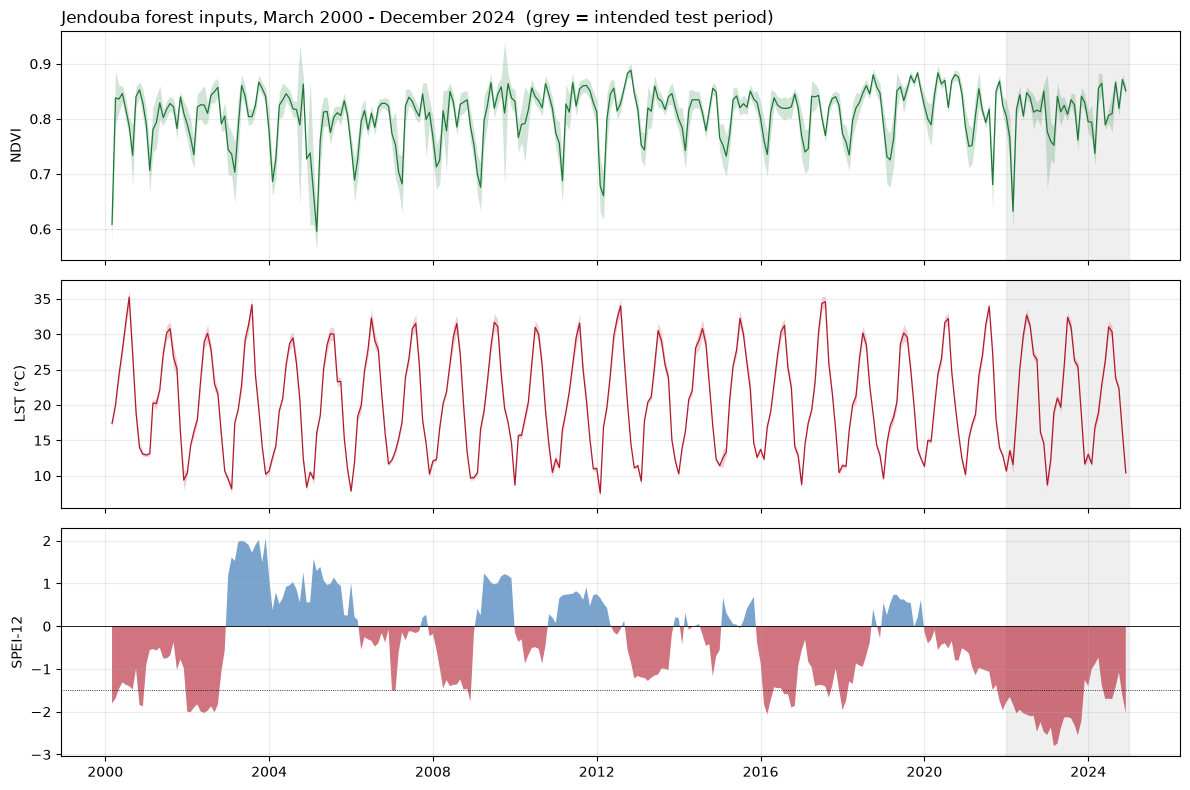

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
d = master.index

TEST_START, TEST_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31")
for ax in axes:
    ax.axvspan(TEST_START, TEST_END, color="grey", alpha=0.12, zorder=0)
    ax.grid(alpha=0.25)

axes[0].plot(d, master["NDVI"], lw=0.9, color="#1b7837")
axes[0].fill_between(d, master["NDVI"] - master["NDVI_sd"],
                        master["NDVI"] + master["NDVI_sd"],
                     color="#1b7837", alpha=0.20, lw=0)
axes[0].set_ylabel("NDVI")

axes[1].plot(d, master["LST"], lw=0.9, color="#b2182b")
axes[1].fill_between(d, master["LST"] - master["LST_sd"],
                        master["LST"] + master["LST_sd"],
                     color="#b2182b", alpha=0.20, lw=0)
axes[1].set_ylabel("LST (°C)")

s = master["SPEI_12"]
axes[2].fill_between(d, s, 0, where=s < 0, color="#b2182b", alpha=0.6,
                     lw=0, interpolate=True)
axes[2].fill_between(d, s, 0, where=s >= 0, color="#2166ac", alpha=0.6,
                     lw=0, interpolate=True)
axes[2].axhline(0, color="k", lw=0.6)
axes[2].axhline(-1.5, color="k", lw=0.6, ls=":")
axes[2].set_ylabel("SPEI-12")

axes[0].set_title("Jendouba forest inputs, March 2000 - December 2024  "
                  "(grey = intended test period)", loc="left")
fig.tight_layout()
fig.savefig("../figures/01_input_series.png", dpi=150, bbox_inches="tight")
plt.show()

### Check 5 — land-cover stability

summer floor:  slope +0.00027/yr   p 0.7840   change over record +0.006
winter peak:  slope +0.00112/yr   p 0.1424   change over record +0.027


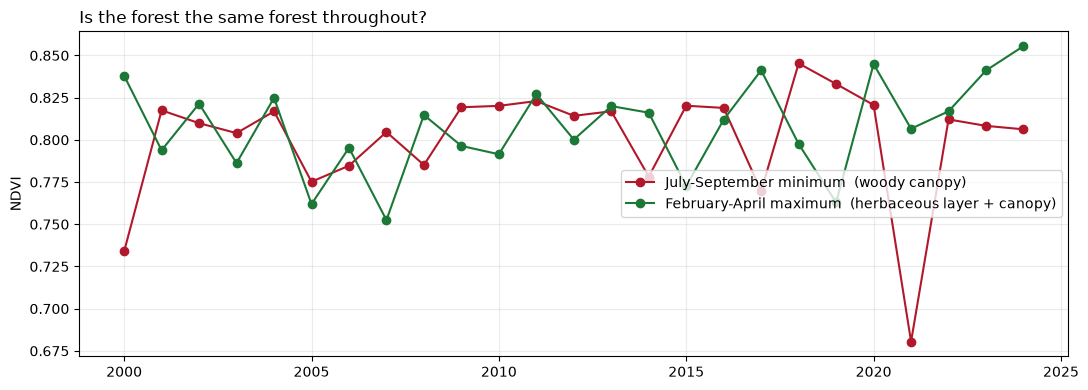

In [11]:
summer = master[master.index.month.isin([7, 8, 9])]
floor = summer.groupby(summer.index.year)["NDVI"].min()

winter = master[master.index.month.isin([2, 3, 4])]
ceiling = winter.groupby(winter.index.year)["NDVI"].max()

for label, s in [("summer floor", floor), ("winter peak", ceiling)]:
    r = linregress(s.index, s.values)
    print(f"{label}:  slope {r.slope:+.5f}/yr   p {r.pvalue:.4f}   "
          f"change over record {r.slope * (s.index[-1] - s.index[0]):+.3f}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(floor.index, floor.values, "o-", color="#b2182b",
        label="July-September minimum  (woody canopy)")
ax.plot(ceiling.index, ceiling.values, "o-", color="#1b7837",
        label="February-April maximum  (herbaceous layer + canopy)")
ax.set_ylabel("NDVI")
ax.grid(alpha=0.25)
ax.legend(loc="center right")
ax.set_title("Is the forest the same forest throughout?", loc="left")
fig.tight_layout()
fig.savefig("../figures/01_land_cover_stability.png", dpi=150, bbox_inches="tight")
plt.show()